In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/eye-diseases-classification/dataset/glaucoma/1255_right.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/1482_left.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_398_8823411.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_309_4110303.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_13_697490.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_205_310538.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/Glaucoma_040.png
/kaggle/input/eye-diseases-classification/dataset/glaucoma/1256_right.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_221_3079640.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_392_9636183.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_12_5295071.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_399_7128170.jpg
/kaggle/input/eye-diseases-classification/dataset/glaucoma/_113_8738972.jpg
/kaggle/input/eye-disea

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
import numpy as np
import matplotlib.pyplot as plt
import json
import os


2025-12-01 14:46:33.368840: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764600393.832371      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764600394.008791      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [3]:
DATASET_PATH = "/kaggle/input/eye-diseases-classification/dataset"
IMAGE_SIZE = 224
BATCH_SIZE = 32


In [4]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)


Found 4217 files belonging to 4 classes.
Using 3374 files for training.


I0000 00:00:1764600417.829749      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1764600417.830357      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 4217 files belonging to 4 classes.
Using 843 files for validation.
Classes: ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']


In [5]:
data_augmentation = tf.keras.Sequential([layers.RandomFlip("horizontal"),
                                         layers.RandomRotation(0.08),
                                         layers.RandomZoom(0.1),
                                         layers.RandomContrast(0.15),], name="augmentation")


In [6]:

def build_model(num_classes):
    base_model = tf.keras.applications.MobileNetV3Large(
        include_top=False,
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        weights="imagenet"
    )

    base_model.trainable = False  

    inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    x = data_augmentation(inputs)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="swish")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    return model, base_model

model, base_model = build_model(num_classes)


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [7]:
train_ds = train_ds.map(lambda x, y: (x, tf.one_hot(tf.cast(y, tf.int32), num_classes)))
val_ds = val_ds.map(lambda x, y: (x, tf.one_hot(tf.cast(y, tf.int32), num_classes)))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


In [8]:
model.compile(
    optimizer=optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)


In [9]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_model.keras",
    monitor="val_accuracy",
    save_best_only=True
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=8,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    patience=4,
    factor=0.4
)


In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint, reduce_lr, early_stopping]
)


Epoch 1/10


I0000 00:00:1764600431.133127     117 cuda_dnn.cc:529] Loaded cuDNN version 90300


106/106 ━━━━━━━━━━━━━━━━━━━━ 28s 164ms/step - accuracy: 0.6465 - loss: 1.0844 - val_accuracy: 0.7853 - val_loss: 0.7844 - learning_rate: 0.0010
Epoch 2/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.7847 - loss: 0.7803 - val_accuracy: 0.8066 - val_loss: 0.7316 - learning_rate: 0.0010
Epoch 3/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step - accuracy: 0.8157 - loss: 0.7195 - val_accuracy: 0.7865 - val_loss: 0.7207 - learning_rate: 0.0010
Epoch 4/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8157 - loss: 0.7147 - val_accuracy: 0.8233 - val_loss: 0.7003 - learning_rate: 0.0010
Epoch 5/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 92ms/step - accuracy: 0.8370 - loss: 0.6837 - val_accuracy: 0.8446 - val_loss: 0.6631 - learning_rate: 0.0010
Epoch 6/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step - accuracy: 0.8248 - loss: 0.6824 - val_accuracy: 0.8292 - val_loss: 0.6685 - learning_rate: 0.0010
Epoch 7/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.8407 - loss: 0.6670 

In [11]:
print(class_names)
print(len(class_names))


['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']
4


In [12]:
import os

for root, dirs, files in os.walk(DATASET_PATH):
    print(root, "->", len(files), "files")


/kaggle/input/eye-diseases-classification/dataset -> 0 files
/kaggle/input/eye-diseases-classification/dataset/glaucoma -> 1007 files
/kaggle/input/eye-diseases-classification/dataset/normal -> 1074 files
/kaggle/input/eye-diseases-classification/dataset/diabetic_retinopathy -> 1098 files
/kaggle/input/eye-diseases-classification/dataset/cataract -> 1038 files


In [13]:
base_model.trainable = True

model.compile(
    optimizer=optimizers.Adam(1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[checkpoint, reduce_lr, early_stopping]
)


Epoch 1/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 57s 249ms/step - accuracy: 0.7195 - loss: 0.9637 - val_accuracy: 0.7224 - val_loss: 0.8353 - learning_rate: 1.0000e-04
Epoch 2/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 24s 227ms/step - accuracy: 0.8704 - loss: 0.6244 - val_accuracy: 0.7177 - val_loss: 0.8692 - learning_rate: 1.0000e-04
Epoch 3/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 24s 230ms/step - accuracy: 0.8979 - loss: 0.5727 - val_accuracy: 0.7426 - val_loss: 0.8145 - learning_rate: 1.0000e-04
Epoch 4/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 25s 231ms/step - accuracy: 0.9220 - loss: 0.5334 - val_accuracy: 0.7817 - val_loss: 0.7616 - learning_rate: 1.0000e-04
Epoch 5/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 25s 233ms/step - accuracy: 0.9326 - loss: 0.5124 - val_accuracy: 0.8031 - val_loss: 0.7568 - learning_rate: 1.0000e-04
Epoch 6/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 25s 235ms/step - accuracy: 0.9446 - loss: 0.4885 - val_accuracy: 0.8292 - val_loss: 0.6859 - learning_rate: 1.0000e-04
Epoch 7/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 25s 23

In [14]:
model.save("mobilenet_final.keras")

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("So , my Model and  class names are saved!")


So , my Model and  class names are saved!


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━

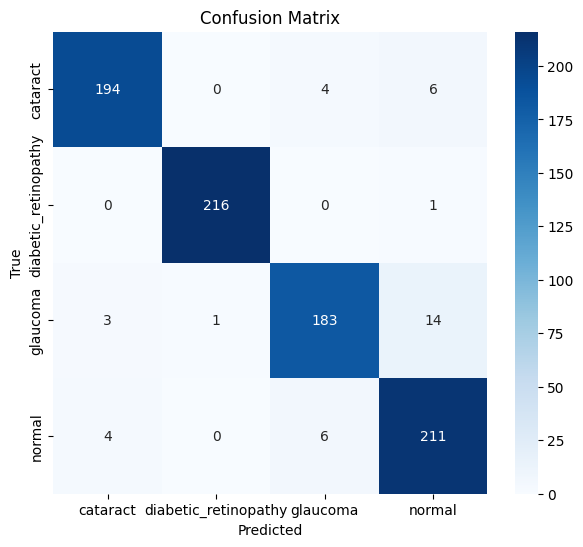

In [15]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


y_true = []
y_pred = []

for images, labels in val_ds:
    
    preds = model.predict(images)

    
    y_pred.extend(np.argmax(preds, axis=1))

    
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)


print("CLASSIFICATION REPORT\n")
print(classification_report(y_true, y_pred, target_names=class_names))


cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


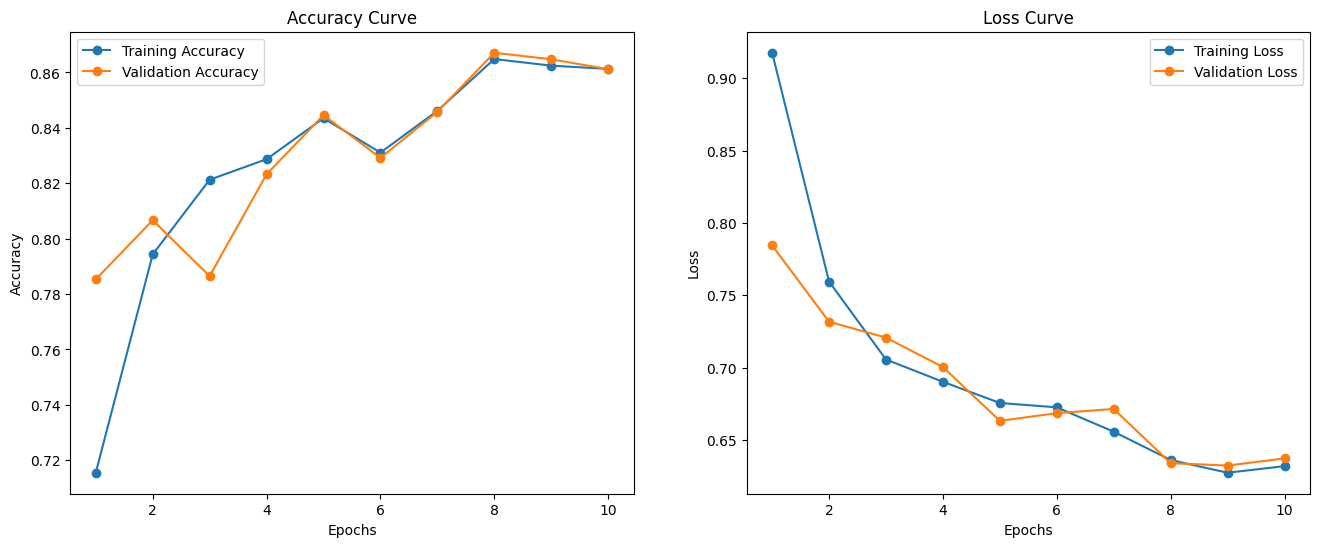

In [16]:
import matplotlib.pyplot as plt

# Training curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'o-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'o-', label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'o-', label='Training Loss')
plt.plot(epochs, val_loss, 'o-', label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


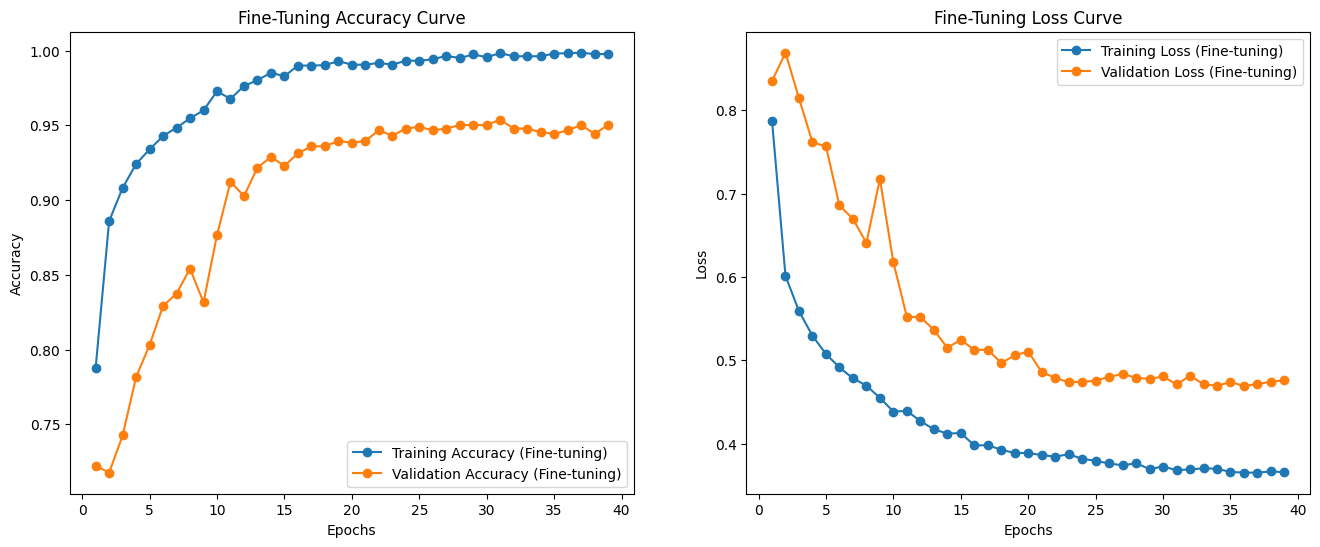

In [17]:
import matplotlib.pyplot as plt

acc_fine = history_fine.history['accuracy']
val_acc_fine = history_fine.history['val_accuracy']
loss_fine = history_fine.history['loss']
val_loss_fine = history_fine.history['val_loss']

epochs_fine = range(1, len(acc_fine) + 1)

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(epochs_fine, acc_fine, 'o-', label='Training Accuracy (Fine-tuning)')
plt.plot(epochs_fine, val_acc_fine, 'o-', label='Validation Accuracy (Fine-tuning)')
plt.title('Fine-Tuning Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_fine, loss_fine, 'o-', label='Training Loss (Fine-tuning)')
plt.plot(epochs_fine, val_loss_fine, 'o-', label='Validation Loss (Fine-tuning)')
plt.title('Fine-Tuning Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


In [18]:
base_model.summary()


Model: "MobileNetV3Large"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ rescaling[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        144 │ activation[0][0]  │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        256 │ re_lu[0][0]       │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_add   │ (None, 112, 112,  │          0 │ activation[0][0], │
│ (Add)               │ 16)               │            │ expanded_conv_pr… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │      1,024 │ expanded_conv_ad… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │        256 │ expanded_conv_1_… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 112, 112,  │          0 │ expanded_conv_1_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 113, 113,  │          0 │ re_lu_1[0][0]     │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        576 │ expanded_conv_1_… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        256 │ expanded_conv_1_

 Total params: 2,996,352 (11.43 MB)

 Trainable params: 2,971,952 (11.34 MB)

 Non-trainable params: 24,400 (95.31 KB)

In [19]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       246,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,681,390 (36.93 MB)

 Trainable params: 3,218,996 (12.28 MB)

 Non-trainable params: 24,400 (95.31 KB)

 Optimizer params: 6,437,994 (24.56 MB)

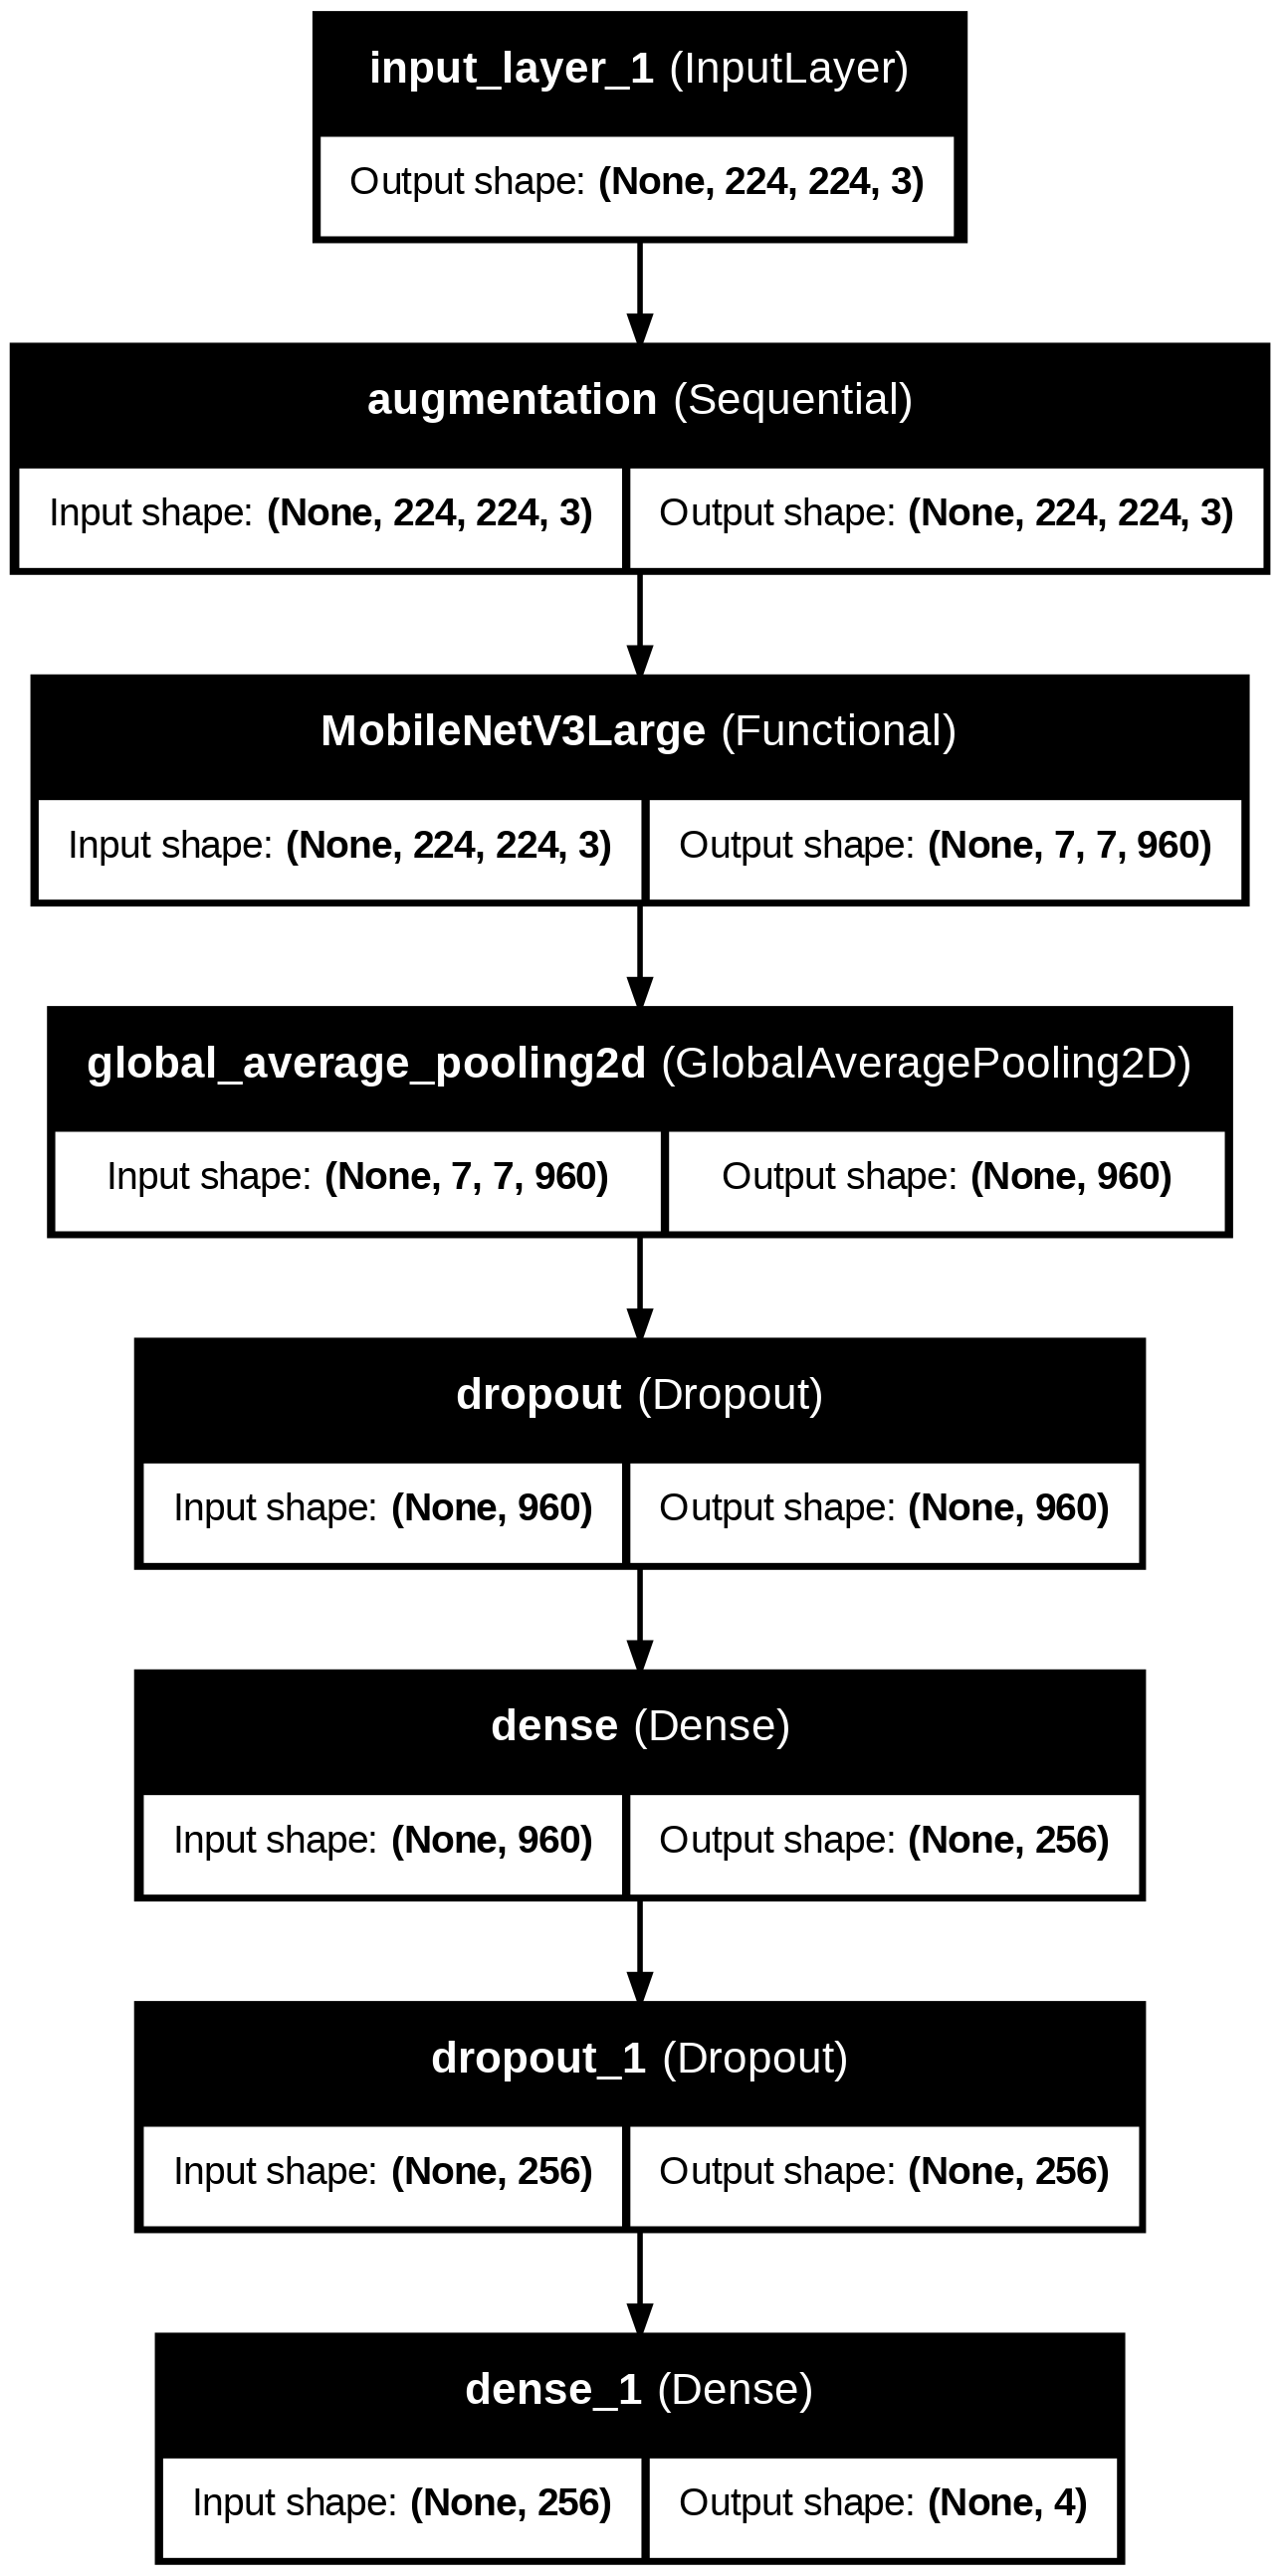

In [20]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file="model_architecture.png",
    show_shapes=True,
    show_layer_names=True
)




In [21]:
tf.keras.utils.plot_model(
    model,
    to_file="model_plot.png",
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True,
    dpi=200
)
